In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("Extended_Employee_Performance_and_Productivity_Data.csv")

# Quick look at the data
df.head()

,Employee_ID,Department,Gender,Age,Job_Title,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned
0,1,IT,Male,55,Specialist,2022-01-19 08:03:05.556036,2,High School,5,6750,33,32,22,2,0,14,66,0,2.63,False
1,2,Finance,Male,29,Developer,2024-04-18 08:03:05.556036,0,High School,5,7500,34,34,13,14,100,12,61,2,1.72,False
2,3,Finance,Male,55,Specialist,2015-10-26 08:03:05.556036,8,High School,3,5850,37,27,6,3,50,10,1,0,3.17,False
3,4,Customer Support,Female,48,Analyst,2016-10-22 08:03:05.556036,7,Bachelor,2,4800,52,10,28,12,100,10,0,1,1.86,False
4,5,Engineering,Female,36,Analyst,2021-07-23 08:03:05.556036,3,Bachelor,2,4800,38,11,29,13,100,15,9,1,1.25,False


In [3]:
# Dataset shape and info
print("Shape:", df.shape)
print("\nColumn info:")
df.info()

print("\nMissing values:")
df.isnull().sum()

Shape: (100000, 20)

Column info:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Employee_ID                  100000 non-null  int64  
 1   Department                   100000 non-null  str    
 2   Gender                       100000 non-null  str    
 3   Age                          100000 non-null  int64  
 4   Job_Title                    100000 non-null  str    
 5   Hire_Date                    100000 non-null  str    
 6   Years_At_Company             100000 non-null  int64  
 7   Education_Level              100000 non-null  str    
 8   Performance_Score            100000 non-null  int64  
 9   Monthly_Salary               100000 non-null  int64  
 10  Work_Hours_Per_Week          100000 non-null  int64  
 11  Projects_Handled             100000 non-null  int64  
 12  Overtime_Hours               100000 

Employee_ID                    0
Department                     0
Gender                         0
Age                            0
Job_Title                      0
Hire_Date                      0
Years_At_Company               0
Education_Level                0
Performance_Score              0
Monthly_Salary                 0
Work_Hours_Per_Week            0
Projects_Handled               0
Overtime_Hours                 0
Sick_Days                      0
Remote_Work_Frequency          0
Team_Size                      0
Training_Hours                 0
Promotions                     0
Employee_Satisfaction_Score    0
Resigned                       0
dtype: int64

In [4]:
df.describe()

,Employee_ID,Age,Years_At_Company,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,41.029410,4.476070,2.995430,6403.211000,44.956950,24.431170,14.514930,7.008550,50.090500,10.013560,49.506060,0.999720,2.999088
std,28867.657797,11.244121,2.869336,1.414726,1372.508717,8.942003,14.469584,8.664026,4.331591,35.351157,5.495405,28.890383,0.815872,1.150719
min,1.000000,22.000000,0.000000,1.000000,3850.000000,30.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000
25%,25000.750000,31.000000,2.000000,2.000000,5250.000000,37.000000,12.000000,7.000000,3.000000,25.000000,5.000000,25.000000,0.000000,2.010000
50%,50000.500000,41.000000,4.000000,3.000000,6500.000000,45.000000,24.000000,15.000000,7.000000,50.000000,10.000000,49.000000,1.000000,3.000000
75%,75000.250000,51.000000,7.000000,4.000000,7500.000000,53.000000,37.000000,22.000000,11.000000,75.000000,15.000000,75.000000,2.000000,3.990000
max,100000.000000,60.000000,10.000000,5.000000,9000.000000,60.000000,49.000000,29.000000,14.000000,100.000000,19.000000,99.000000,2.000000,5.000000


In [5]:
# Check resignation distribution
print(df['Resigned'].value_counts())
print("\nResignation rate:", round(df['Resigned'].mean() * 100, 2), "%")

Resigned
False    89990
True     10010
Name: count, dtype: int64

Resignation rate: 10.01 %


In [6]:
dept_summary = df.groupby('Department').agg(
    Total_Employees=('Employee_ID', 'count'),
    Avg_Salary=('Monthly_Salary', 'mean'),
    Avg_Performance=('Performance_Score', 'mean'),
    Resignation_Rate=('Resigned', 'mean')
).round(2)

dept_summary['Resignation_Rate'] = (dept_summary['Resignation_Rate'] * 100).round(2)
dept_summary.sort_values('Resignation_Rate', ascending=False)

,Total_Employees,Avg_Salary,Avg_Performance,Resignation_Rate
Department,,,,
Finance,11200,6398.58,2.98,11.0
Customer Support,11116,6403.88,3.00,10.0
Engineering,10956,6417.25,3.02,10.0
HR,10960,6400.36,3.00,10.0
IT,11131,6414.60,3.00,10.0
Legal,11118,6391.28,2.98,10.0
Marketing,11216,6377.86,2.98,10.0
Operations,11181,6412.31,3.01,10.0
Sales,11122,6413.15,2.99,10.0


In [7]:
# Overtime vs Resignation
overtime_summary = df.groupby('Resigned').agg(
    Avg_Overtime_Hours=('Overtime_Hours', 'mean'),
    Avg_Satisfaction=('Employee_Satisfaction_Score', 'mean'),
    Avg_Work_Hours=('Work_Hours_Per_Week', 'mean'),
    Avg_Performance=('Performance_Score', 'mean')
).round(2)

overtime_summary

,Avg_Overtime_Hours,Avg_Satisfaction,Avg_Work_Hours,Avg_Performance
Resigned,,,,
False,14.51,3.00,44.96,3.00
True,14.58,2.99,44.96,2.98


In [8]:
remote_summary = df.groupby('Remote_Work_Frequency').agg(
    Total_Employees=('Employee_ID', 'count'),
    Resignation_Rate=('Resigned', 'mean')
).round(3)

remote_summary['Resignation_Rate'] = (remote_summary['Resignation_Rate'] * 100).round(2)
remote_summary

,Total_Employees,Resignation_Rate
Remote_Work_Frequency,,
0,19837,9.5
25,20235,10.1
50,19706,10.0
75,20173,10.3
100,20049,10.2


In [9]:
# Resignation by Job Title
job_summary = df.groupby('Job_Title').agg(
    Total_Employees=('Employee_ID', 'count'),
    Resignation_Rate=('Resigned', 'mean'),
    Avg_Salary=('Monthly_Salary', 'mean')
).round(2)
job_summary['Resignation_Rate'] = (job_summary['Resignation_Rate'] * 100).round(2)
job_summary.sort_values('Resignation_Rate', ascending=False)

,Total_Employees,Resignation_Rate,Avg_Salary
Job_Title,,,
Analyst,14261,10.0,5195.82
Consultant,14210,10.0,7152.09
Developer,14195,10.0,6490.14
Engineer,14217,10.0,7799.32
Manager,14325,10.0,7798.32
Specialist,14507,10.0,5855.34
Technician,14285,10.0,4545.15


In [10]:
# Create tenure buckets
df['Tenure_Group'] = pd.cut(df['Years_At_Company'], 
                              bins=[-1, 1, 3, 5, 10], 
                              labels=['0-1 yrs', '2-3 yrs', '4-5 yrs', '6-10 yrs'])

tenure_summary = df.groupby('Tenure_Group', observed=True).agg(
    Total_Employees=('Employee_ID', 'count'),
    Resignation_Rate=('Resigned', 'mean')
).round(3)
tenure_summary['Resignation_Rate'] = (tenure_summary['Resignation_Rate'] * 100).round(2)
tenure_summary

,Total_Employees,Resignation_Rate
Tenure_Group,,
0-1 yrs,20101,10.1
2-3 yrs,20207,10.0
4-5 yrs,19995,9.9
6-10 yrs,39697,10.0


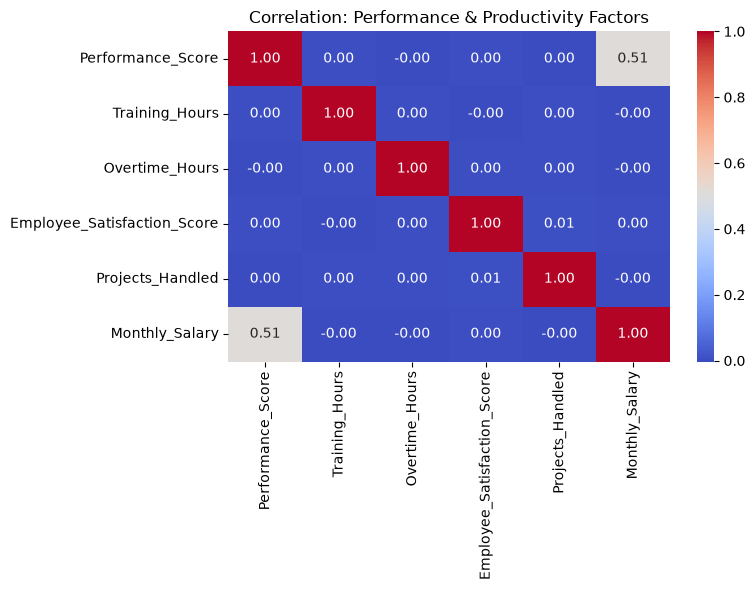

In [11]:
# Correlation between performance and other factors
numeric_cols = ['Performance_Score', 'Training_Hours', 'Overtime_Hours', 
                 'Employee_Satisfaction_Score', 'Projects_Handled', 'Monthly_Salary']
correlation = df[numeric_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation: Performance & Productivity Factors')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150)
plt.show()

In [12]:
salary_by_edu = df.groupby('Education_Level').agg(
    Avg_Salary=('Monthly_Salary', 'mean'),
    Avg_Performance=('Performance_Score', 'mean'),
    Count=('Employee_ID', 'count')
).round(2).sort_values('Avg_Salary', ascending=False)
salary_by_edu

,Avg_Salary,Avg_Performance,Count
Education_Level,,,
PhD,6431.55,2.99,5051
Master,6417.45,3.02,14904
High School,6399.36,3.00,30004
Bachelor,6398.42,2.99,50041


In [4]:
import pandas as pd

# Load the dataset
df = pd.read_csv("Extended_Employee_Performance_and_Productivity_Data.csv")

# Recreate the tenure bucket column used in the analysis
df['Tenure_Group'] = pd.cut(df['Years_At_Company'],
                            bins=[-1, 1, 3, 5, 10],
                            labels=['0-1 yrs', '2-3 yrs', '4-5 yrs', '6-10 yrs'])

# Export for Power BI
df.to_csv('cleaned_employee_data.csv', index=False)
print("Exported successfully. Shape:", df.shape)

Exported successfully. Shape: (100000, 21)
